# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import SwimmingPoolAndCarDetectionDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 3748


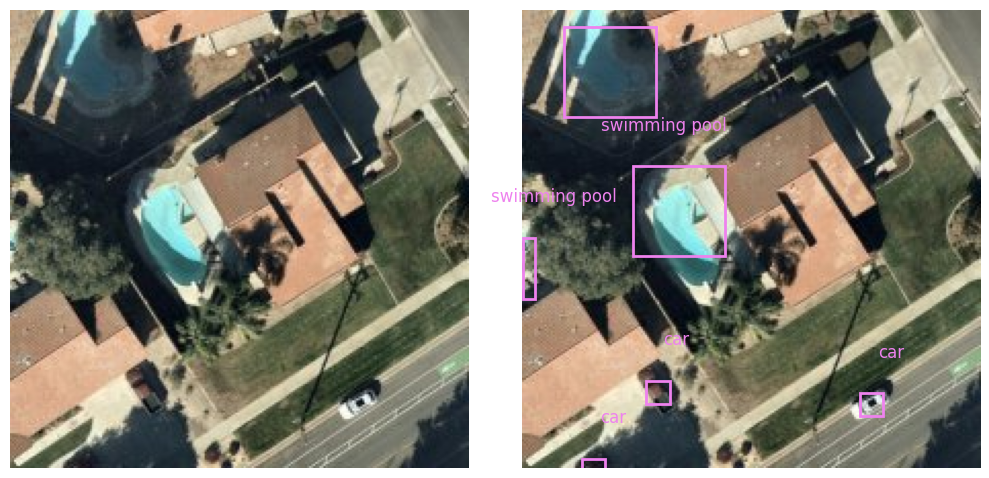

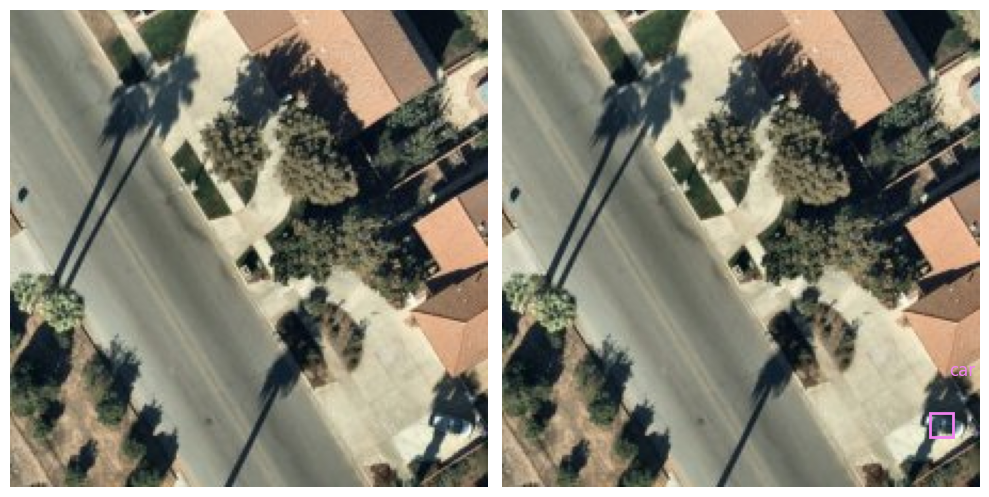

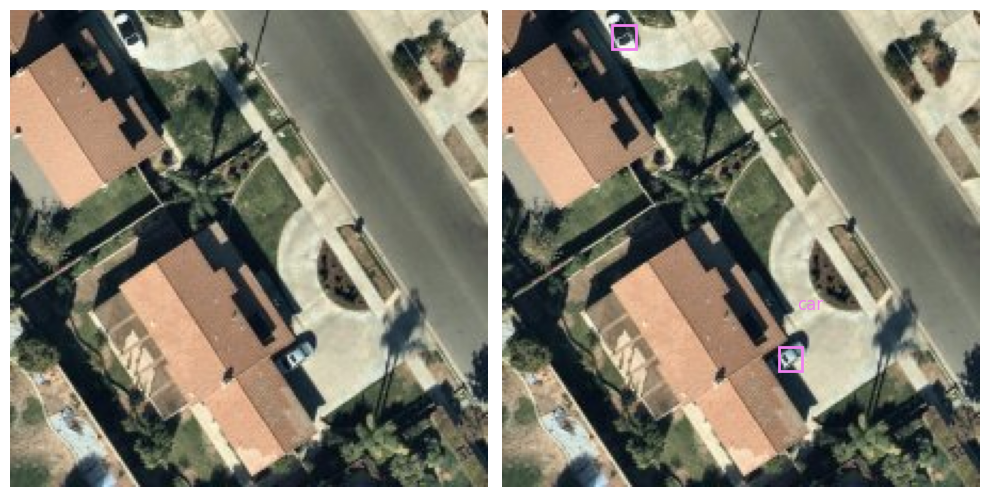

In [ ]:
dataset_config = {
    "image_dir": "./data/swimming_pool_and_car/train/images",
    "annotations_dir": "./data/swimming_pool_and_car/train/labels/",
}
dataset = SwimmingPoolAndCarDetectionDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(100);

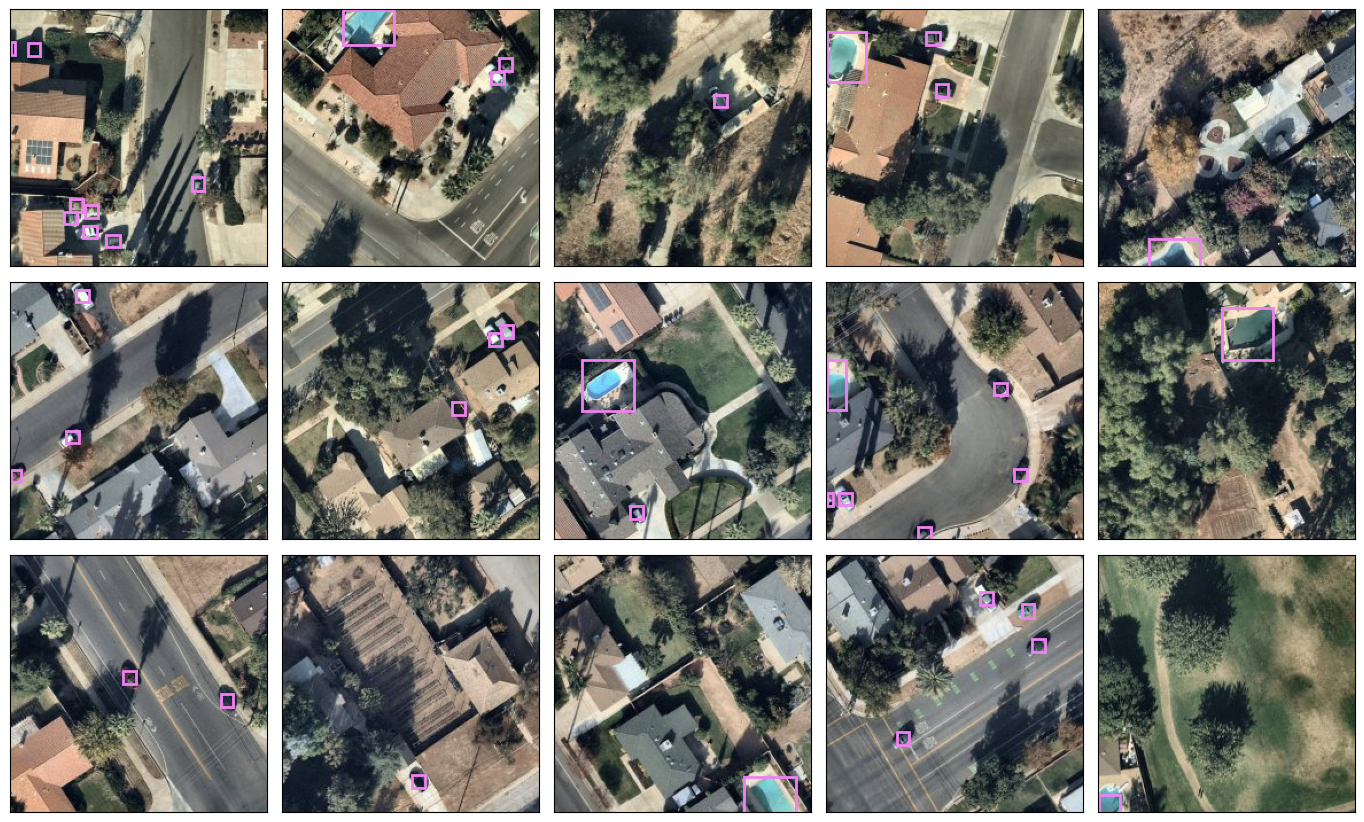

In [21]:
dataset.show_batch(15);

In [22]:
dataset.data_distribution_table()

,Label,Count
0,swimming pool,3107
1,car,12896


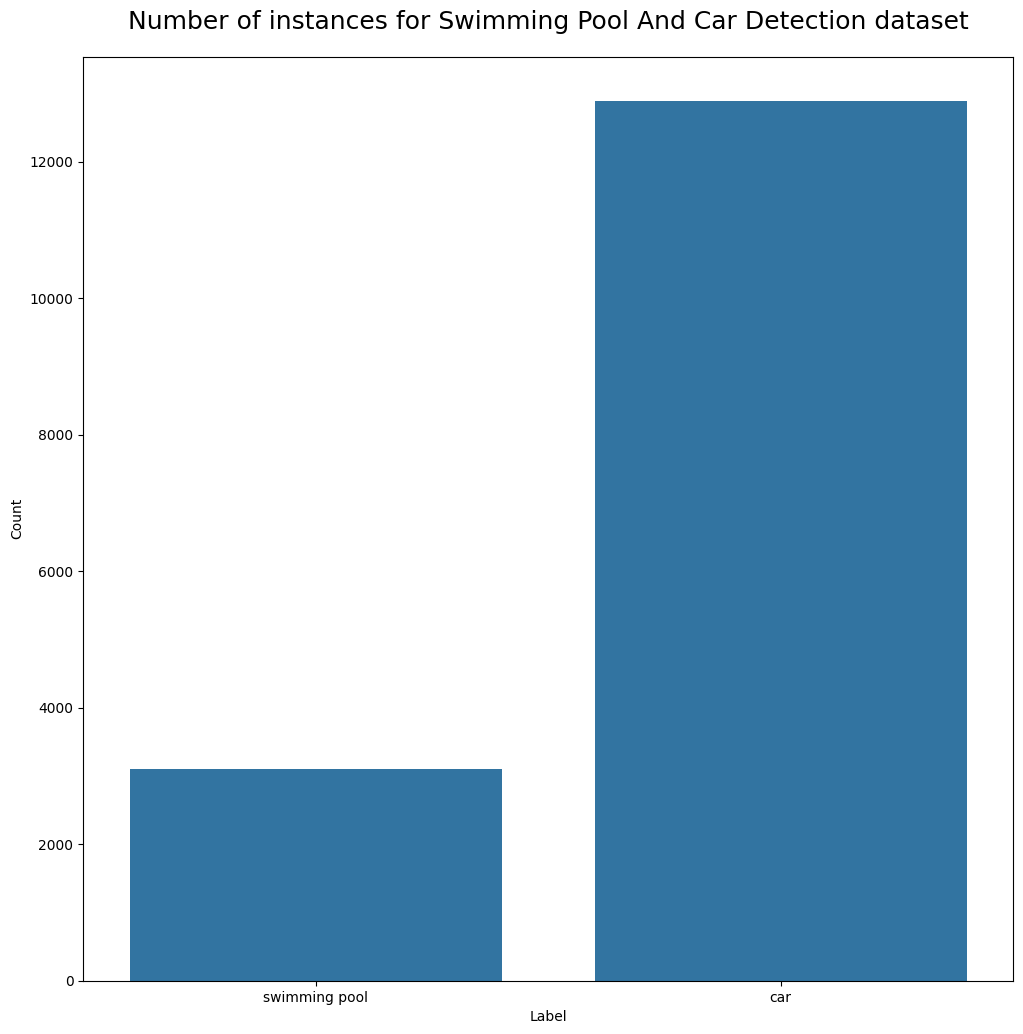

In [23]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "image_dir": "./data/swimming_pool_and_car/train/images",
    "annotations_dir": "./data/swimming_pool_and_car/train/labels/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = SwimmingPoolAndCarDetectionDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 3736


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/swimming_pool_and_car/experiments/"
model_config = {
    "num_classes": 3,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [40]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-26 12:56:15,215 INFO Starting training.
training: 100%|██████████| 467/467 [02:35<00:00,  3.00it/s]
2025-05-26 12:58:51,117 INFO epoch: 1, time: 156, loss:  0.25167
testing on train set: 100%|██████████| 467/467 [01:21<00:00,  5.73it/s]
2025-05-26 13:00:25,800 INFO map:0.5151991248130798, map_50:0.8710080981254578, map_75:0.5621494650840759, map_small:0.282304584980011, map_medium:0.5522122979164124, map_large:0.5584902167320251, mar_1:0.27414873242378235, mar_10:0.5263602137565613, mar_100:0.5925694108009338, mar_small:0.3496936857700348, mar_medium:0.6379539370536804, mar_large:0.6267856955528259, map_per_class:tensor(0.5005), tensor(0.5299), mar_100_per_class:tensor(0.5797), tensor(0.6055), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32)
training: 100%|██████████| 467/467 [02:35<00:00,  3.00it/s]
2025-05-26 13:03:01,680 INFO epoch: 2, time: 156, loss:  0.16648
testing on train set: 100%|██████████| 467/467 [01:22<00:00,  5.65it/s]
2025-05-26 13:04:35,225 I

## Predictions

2025-05-26 13:37:37,465 INFO Loading checkpoint /home/dragik/data/FAIR_EO/swimming_pool_and_car/experiments/checkpoint.pth.tar
2025-05-26 13:37:37,760 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/swimming_pool_and_car/experiments/checkpoint.pth.tar at epoch 11


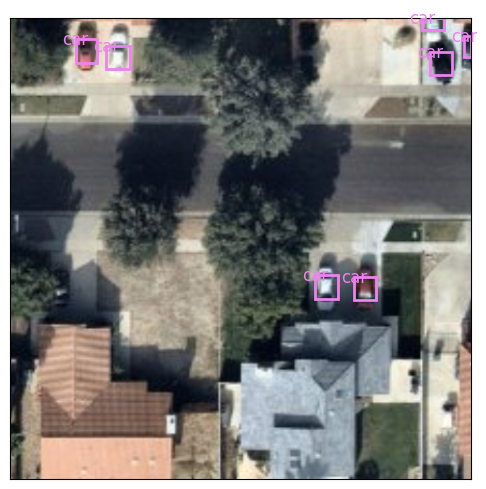

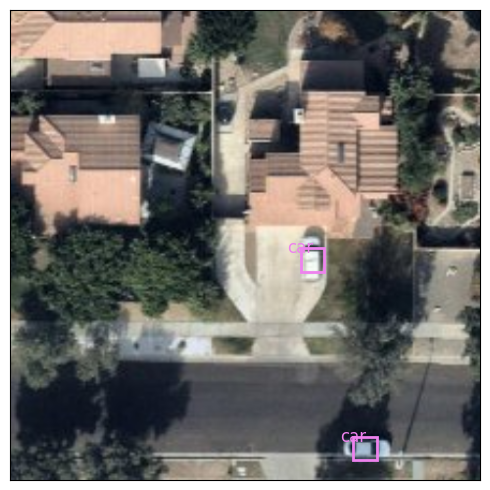

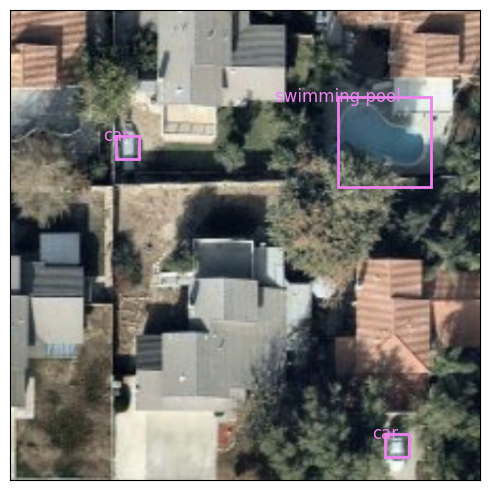

In [ ]:
model_config = {
    "num_classes": 3, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/swimming_pool_and_car/experiments/checkpoint.pth.tar"
labels = ['no-data','swimming pool','car']
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/swimming_pool_and_car/test/images/000000006.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/swimming_pool_and_car/test/images/000000015.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/swimming_pool_and_car/test/images/000000041.jpg')
fig = model.detect_objects(image, labels, transform)